# Opdracht 2 : Voorspel verhuur aantallen


## Teamgegevens

* **teamnaam in kaggle: JAV** 
* **Teamleden met kaggle gebruikersnamen:**
  * Jakub Rebelski (jakubrebelski1)
  * Arda Bagci (Muhammed Arda Bağcı)
  * Vito van Herwerden (Vito van Herwerden)



## Inleiding

In dit project treden wij op als junior data scientists voor CityBike, een aanbieder van deelfietsen. Ons doel is om een voorspellend model te ontwikkelen dat zo nauwkeurig mogelijk het aantal verhuurde fietsen per uur voorspelt, gebaseerd op historische verhuurcijfers, tijdstippen en weersgegevens.

Een sterk voorspellend model kan CityBike gericht helpen bij het slim beheren van de fietsenvloot, zoals het op tijd herverdelen van fietsen en het inplannen van onderhoud. Omdat verkeerde voorspellingen in de praktijk directe gevolgen hebben (zoals lege stations tijdens de spits of juist onnodige kosten door overcapaciteit), vereist deze opdracht een kritische blik op de tijdreeksdata, de gemaakte keuzes en de uiteindelijke betrouwbaarheid van het model.

Dit project vormt tevens onze inzending voor de Kaggle-competitie van de opleiding Applied Data Science & AI. In dit notebook documenteren we ons volledige proces: van de initiële Exploratieve Data Analyse (EDA) en tijdserie-analyse tot het trainen, evalueren en verantwoorden van ons best presterende model.

## Imports
Hier laden we alle benodigde Python-bibliotheken in die we gebruiken voor de data-analyse en het trainen van de modellen die we later nodig gaan hebben.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data inladen
Voor dit project maken we gebruik van drie bestanden die voor de Kaggle-competitie beschikbaar zijn gesteld. We laden deze direct aan het begin in.


In [4]:
df = pd.read_csv('../Data/train.csv')
df_test = pd.read_csv('../Data/test.csv')
df_submission = pd.read_csv('../Data/sample_submission.csv')

# Hier controleren we of de data correct is ingeladen
df.head()

,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


# 1. Opdracht 1: Exploratieve Data Analyse


## 1.1 Datatypes en basisstatistieken

We beginnen de EDA met een eerste check van de trainingsdata (`train.csv`). Hiervoor hebben we de class `BikeEDA` aangemaakt, zodat we alle stappen van onze analyse netjes op één plek hebben.

In deze eerste stap bekijken we de datatypes, de basisstatistieken van alle kolommen en controleren we of er missende waardes of dubbele rijen in de dataset zitten.

In [5]:
class BikeEDA:
    """Class voor het inspecteren, opschonen en visualiseren van fietsdata."""

    def __init__(self, dataframe):
        """Sla een kopie van de dataset op."""
        self.df = dataframe.copy()

    def inspect_data(self):
        """Toon datatypes, basisstatistieken, missende waardes en duplicaten."""
        print(f"Vorm (rijen, kolommen): {self.df.shape}\n")

        # Datatypes en aantal ingevulde waardes per kolom bekijken
        print("Datatypes:")
        self.df.info()

        # Basisstatistieken van alle kolommen (inclusief tekstkolommen)
        print("\nBasisstatistieken:")
        display(self.df.describe(include="all"))

        # Controleren op missende waardes en dubbele rijen
        missing = self.df.isnull().sum()
        duplicates = self.df.duplicated().sum()
        print(f"Missende waardes per kolom:\n{missing}\n")
        print(f"Aantal dubbele rijen: {duplicates}\n")

In [6]:
eda = BikeEDA(df)
eda.inspect_data()

Vorm (rijen, kolommen): (16637, 8)

Datatypes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date_hour   16637 non-null  object 
 1   holiday     16637 non-null  int64  
 2   weathersit  16637 non-null  int64  
 3   temp        16637 non-null  float64
 4   atemp       16637 non-null  float64
 5   hum         16637 non-null  float64
 6   windspeed   16637 non-null  float64
 7   cnt         16637 non-null  int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 1.0+ MB

Basisstatistieken:


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
unique,16637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2012-11-30 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755
min,NaN,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,NaN,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,NaN,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,NaN,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000


Missende waardes per kolom:
date_hour     0
holiday       0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64

Aantal dubbele rijen: 0



## 1.2 Tijdserie-elementen toevoegen

In de vorige stap zagen we dat de kolom `date_hour` nog is opgeslagen als tekst (`object`). Om patronen over de tijd goed te kunnen onderzoeken, zoals spitsuren, weekenden of seizoenen, moeten we deze kolom eerst omzetten naar een echt datum- en tijdformaat (`datetime`).

Hiervoor schrijven we een functie die `date_hour` omzet en er direct een aantal losse tijdelementen uithaalt: het jaar, de maand, de dag van de week, het uur en of het weekend is. Zo kunnen we deze straks makkelijk visualiseren.

In [7]:
def add_time_features(dataframe):
    """Zet date_hour om naar datetime en voeg tijdelementen toe."""
    df_copy = dataframe.copy()
    df_copy["date_hour"] = pd.to_datetime(df_copy["date_hour"])

    df_copy["year"] = df_copy["date_hour"].dt.year
    df_copy["month"] = df_copy["date_hour"].dt.month
    df_copy["day_of_week"] = df_copy["date_hour"].dt.dayofweek
    df_copy["hour"] = df_copy["date_hour"].dt.hour
    df_copy["is_weekend"] = df_copy["day_of_week"].isin([5, 6]).astype(int)

    # Tijdkolom als index zetten en chronologisch sorteren
    df_copy = df_copy.set_index("date_hour").sort_index()
    

    return df_copy

In [8]:
df_eda = add_time_features(df)
df_eda.head()

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day_of_week,hour,is_weekend
date_hour,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,5,0,1
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,5,1,1
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,5,2,1
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,5,3,1
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,5,4,1


## 1.3 Tijdspatronen visualiseren

Nu we de tijdelementen hebben toegevoegd, plotten we de verhuuraantallen over verschillende tijdschalen. We gebruiken hiervoor lijngrafieken om trends, seizoenen en dagelijkse patronen te laten zien te maken.


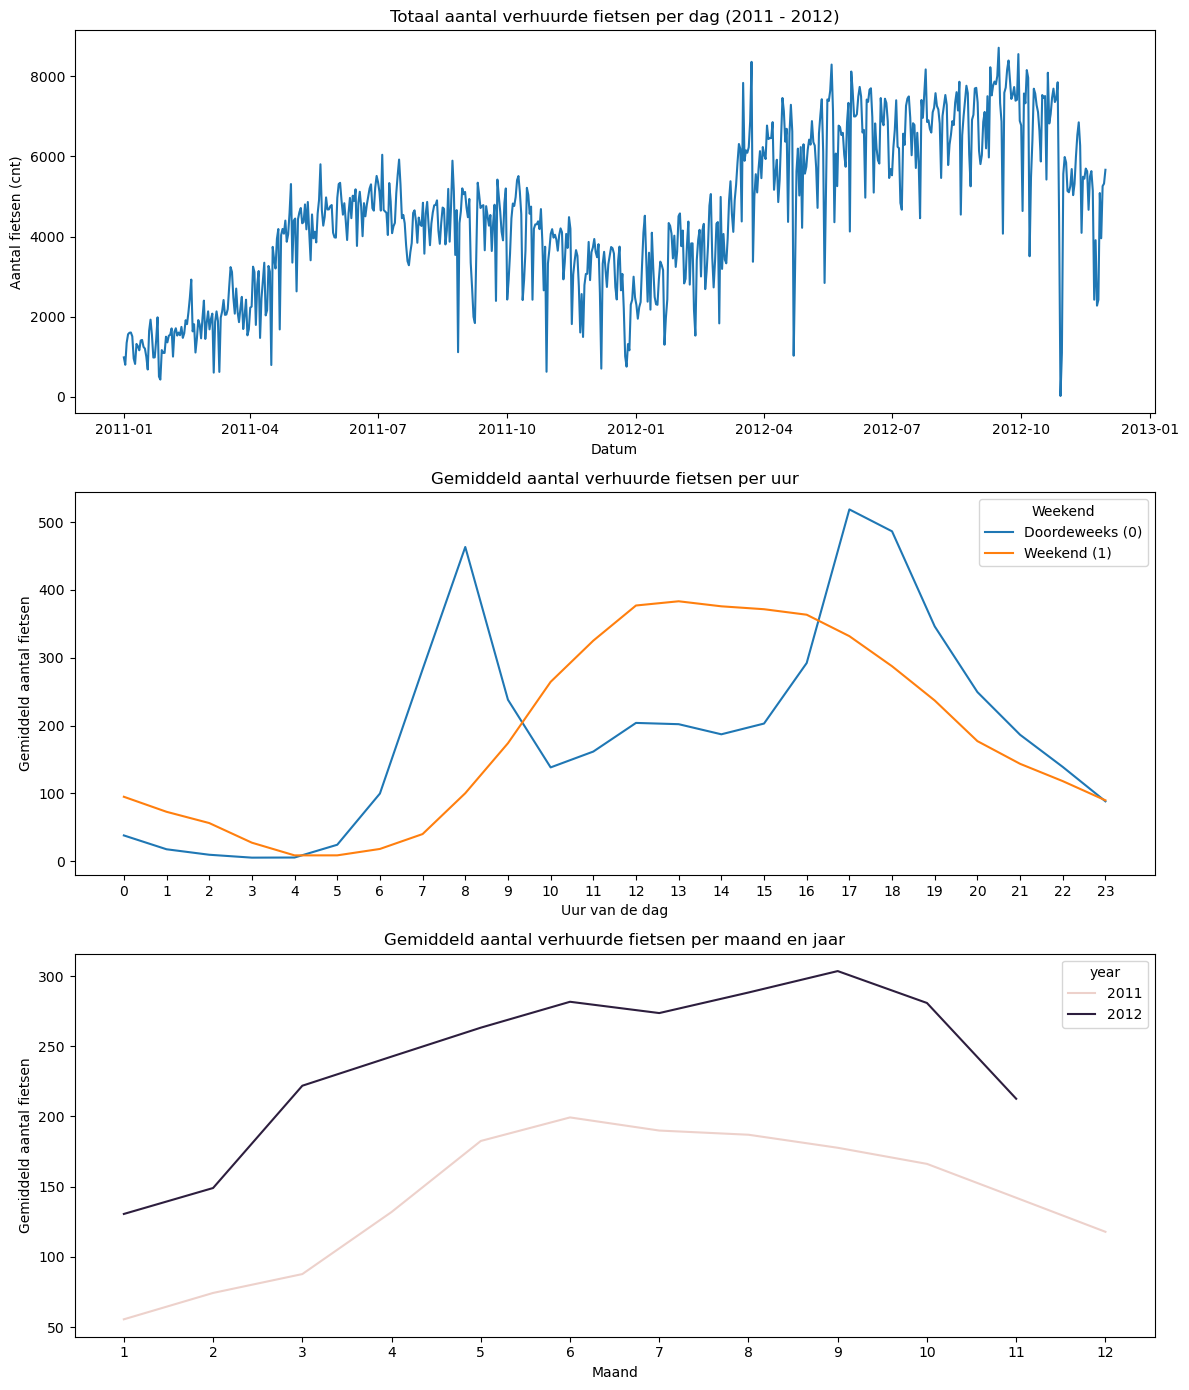

In [ ]:
def plot_time_patterns(dataframe):
    """Plot het verloop per dag, per uur (weekend vs. doordeweeks) en per maand."""
    fig, axes = plt.subplots(3, 1, figsize=(12, 14))

    # 1. Dagelijks totaal over de hele periode (resample("D") groepeert per dag)
    daily_cnt = dataframe["cnt"].resample("D").sum()
    axes[0].plot(daily_cnt.index, daily_cnt.values)
    axes[0].set_title("Totaal aantal verhuurde fietsen per dag (2011 - 2012)")
    axes[0].set_xlabel("Datum")
    axes[0].set_ylabel("Aantal fietsen (cnt)")

    # 2. Gemiddelde per uur: doordeweeks en weekend
    sns.lineplot(
        data=dataframe,
        x="hour",
        y="cnt",
        hue="is_weekend",
        ax=axes[1],
        errorbar=None,
    )
    axes[1].set_title("Gemiddeld aantal verhuurde fietsen per uur")
    axes[1].set_xlabel("Uur van de dag")
    axes[1].set_ylabel("Gemiddeld aantal fietsen")
    axes[1].set_xticks(range(0, 24))
    axes[1].legend(title="Weekend", labels=["Doordeweeks (0)", "Weekend (1)"])

    # 3. Gemiddelde per maand, gesplitst per jaar
    sns.lineplot(
        data=dataframe,
        x="month",
        y="cnt",
        hue="year",
        ax=axes[2],
        errorbar=None,
    )
    axes[2].set_title("Gemiddeld aantal verhuurde fietsen per maand en jaar")
    axes[2].set_xlabel("Maand")
    axes[2].set_ylabel("Gemiddeld aantal fietsen")
    axes[2].set_xticks(range(1, 13))

    plt.tight_layout()
    plt.show()


plot_time_patterns(df_eda)


**Observaties tijdspatronen:**
* **Trend:** In 2012 worden er gemiddeld meer fietsen verhuurd dan in 2011. Er vind dus een duidelijke stijgende trend plaats in de data.
* **Seizoenen:** In de warmere maanden (mei t/m oktober) worden er gemiddeld meer fietsen verhuurd dan in de winter.
* **Dagpatroon:** Doordeweeks zijn er twee duidelijke pieken tijdens de ochtend- en avondspits (08:00 en 17:00-18:00). In het weekend ligt de piek juist midden op de dag tussen 12:00 en 16:00.
* **Uitschieter:** Eind oktober 2012 is er een extreme dip richting 0 verhuurde fietsen.

## 1.4 Relaties tussen de features en cnt

Nu bekijken we hoe de andere kolommen samenhangen met het aantal verhuurde fietsen (`cnt`). Voor de numerieke kolommen (`temp`, `atemp`, `hum`, `windspeed`) gebruiken we een Pearson-correlatiematrix en scatterplots. Voor `weathersit` en `holiday` gebruiken we boxplots, omdat dit geen gewone numerieke waardes zijn maar categorieën.


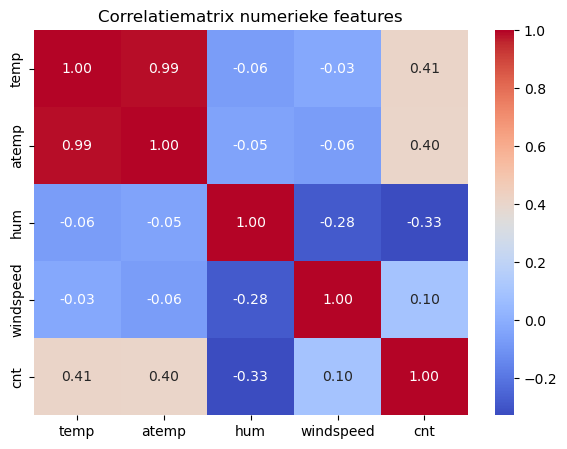

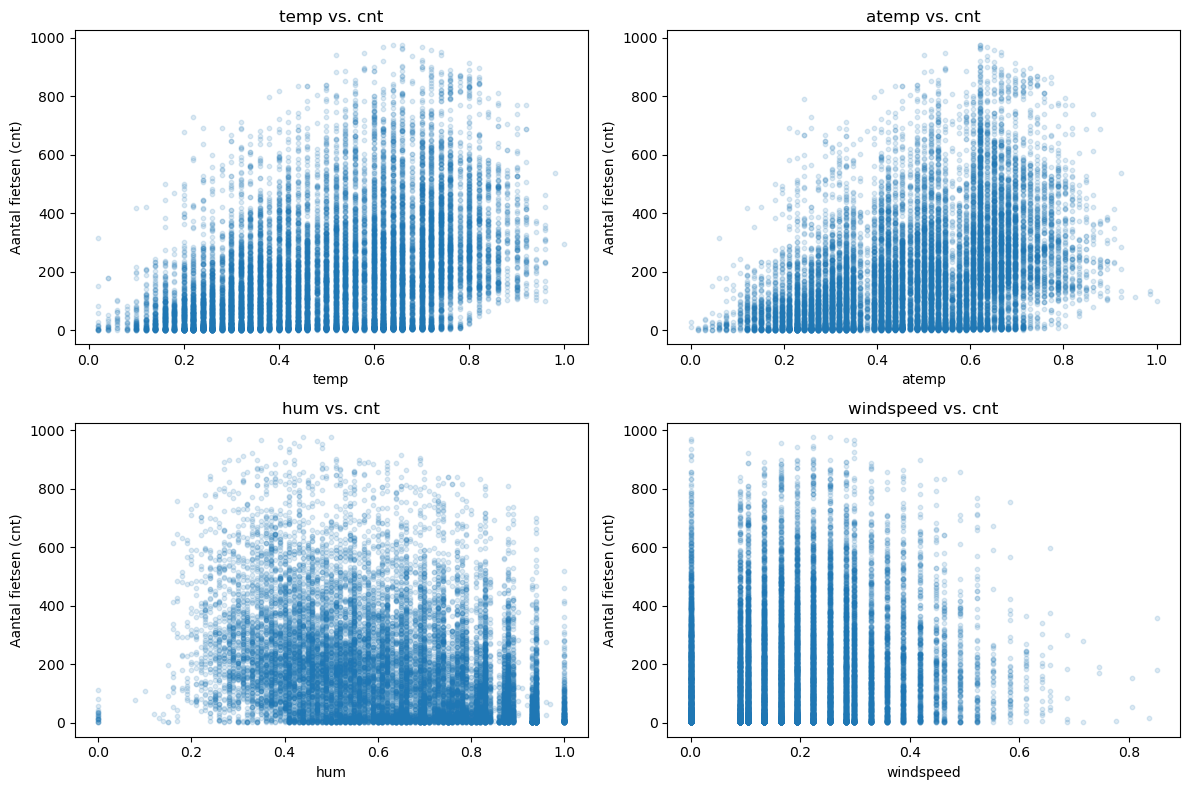

In [10]:
def plot_numeric_relations(dataframe):
    """Plot een correlatiematrix en scatterplots voor numerieke features."""
    num_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

    # 1. Correlatiematrix (alleen numerieke kolommen)
    plt.figure(figsize=(7, 5))
    corr_matrix = dataframe[num_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlatiematrix numerieke features")
    plt.show()

    # 2. Scatterplots van iedere numerieke feature tegen cnt
    features = ["temp", "atemp", "hum", "windspeed"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for ax, col in zip(axes.flatten(), features):
        # alpha=0.15 maakt punten transparant zodat drukke plekken zichtbaar zijn
        ax.scatter(dataframe[col], dataframe["cnt"], alpha=0.15, s=10)
        ax.set_title(f"{col} vs. cnt")
        ax.set_xlabel(col)
        ax.set_ylabel("Aantal fietsen (cnt)")

    plt.tight_layout()
    plt.show()


plot_numeric_relations(df_eda)

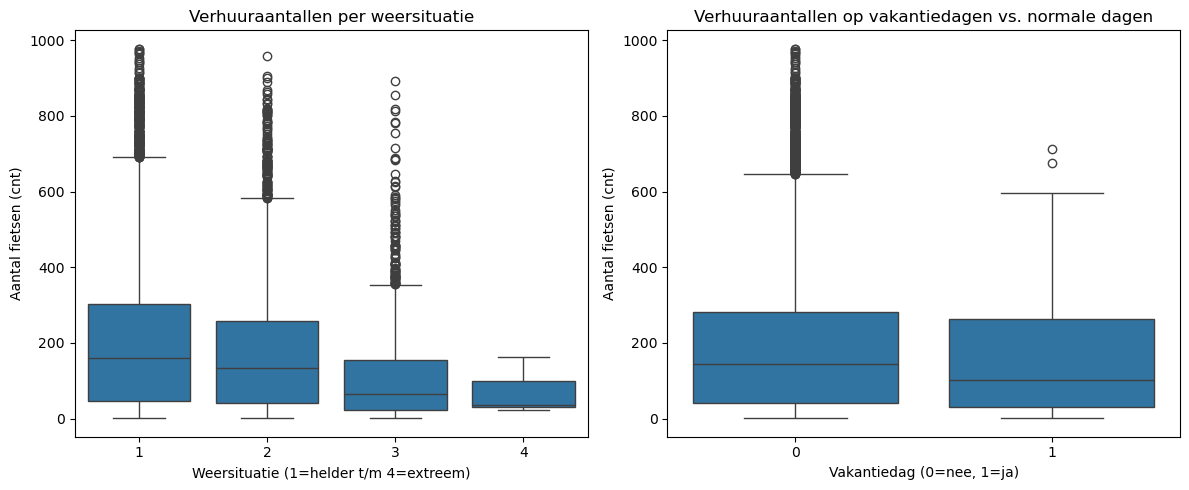

In [11]:
def plot_categorical_relations(dataframe):
    """Plot boxplots voor weathersit en holiday tegen cnt."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(data=dataframe, x="weathersit", y="cnt", ax=axes[0])
    axes[0].set_title("Verhuuraantallen per weersituatie")
    axes[0].set_xlabel("Weersituatie (1=helder t/m 4=extreem)")
    axes[0].set_ylabel("Aantal fietsen (cnt)")

    sns.boxplot(data=dataframe, x="holiday", y="cnt", ax=axes[1])
    axes[1].set_title("Verhuuraantallen op vakantiedagen vs. normale dagen")
    axes[1].set_xlabel("Vakantiedag (0=nee, 1=ja)")
    axes[1].set_ylabel("Aantal fietsen (cnt)")

    plt.tight_layout()
    plt.show()


plot_categorical_relations(df_eda)

Uit de correlatiematrix, scatterplots en boxplots vallen een paar dingen op:
- `temp` en `atemp` hebben een correlatie van 0.99 en bevatten dus bijna dezelfde informatie. Beide hebben een positief verband met `cnt` (hoe warmer, hoe meer fietsen er worden verhuurd).
- `hum` heeft een negatief verband met `cnt` (-0.33): bij hogere luchtvochtigheid wordt er minder gefietst. In de scatterplot staan een paar punten op precies 0.0, wat waarschijnlijk meetfouten zijn.
- `windspeed` heeft een lage lineaire correlatie (0.10) en heel veel waardes op precies 0.0, met een gat tot ongeveer 0.09. We verwijderen deze kolom niet direct op basis van de correlatie, maar houden wel rekening met die nullen.
- Bij `weathersit` zakt het aantal verhuurde fietsen duidelijk zodra het weer slechter wordt (van categorie 1 naar 4).
- Op vakantiedagen (`holiday = 1`) ligt de mediaan iets lager dan op gewone dagen en zijn er veel minder hoge pieken.

## 1.5 Data opschonen

Uit de grafieken zagen we een paar opvallende punten, zoals nullen bij `hum` en `windspeed`, en bijna geen datapunten bij `weathersit == 4`. Daarnaast willen we weten of er uren ontbreken in de tijdreeks. We schrijven eerst een functie om deze aantallen precies te tellen, zodat we daarna kunnen bepalen wat we opschonen.

In [ ]:
def check_data_issues(dataframe):
    """Tel opvallende waardes en ontbrekende uren in de dataset."""
    # Aantal rijen met 0 bij luchtvochtigheid en windsnelheid
    hum_zero = (dataframe["hum"] == 0).sum()
    wind_zero = (dataframe["windspeed"] == 0).sum()

    # Aantal rijen per weersituatie
    weather_counts = dataframe["weathersit"].value_counts().sort_index()

    # Controleren hoeveel uren er ontbreken
    full_range = pd.date_range(
        start=dataframe.index.min(),
        end=dataframe.index.max(),
        freq="h",
    )
    missing_hours = len(full_range.difference(dataframe.index))

    print(f"Aantal rijen met hum == 0: {hum_zero}")
    print(f"Aantal rijen met windspeed == 0: {wind_zero}")
    print(f"Aantal ontbrekende uren in de tijdlijn: {missing_hours}\n")
    print("Verdeling weathersit:")
    print(weather_counts)


check_data_issues(df_eda)

Aantal rijen met hum == 0: 22
Aantal rijen met windspeed == 0: 2072
Aantal ontbrekende uren in de tijdlijn: 163

Verdeling weathersit:
weathersit
1    11078
2     4207
3     1349
4        3
Name: count, dtype: int64


Op basis van deze aantallen maken we de volgende keuzes voor het opschonen:
- `atemp` halen we weg, omdat deze een correlatie van 0.99 heeft met `temp` en dus bijna dezelfde informatie geeft. Zo voorkomen we overfitting.
- De 22 rijen waar `hum` precies 0 is zijn meetfouten. Deze zetten we om naar `NaN` en vullen we op met het gemiddelde van de uren ervoor en erna.
- `windspeed == 0` komt 2072 keer voor (ruim 12% van de data). Omdat het ook gewoon windstil kan zijn, laten we deze staan.
- `weathersit == 4` komt maar 3 keer voor, wat te weinig is om goed van te leren. Deze voegen we samen met categorie 3 (slecht weer).
- De 163 ontbrekende uren vullen we hier nog niet aan, zodat we geen verzonnen data aan de normale ML-modellen geven. Bij de tijdseriemodellen in opdracht 2 en 3 lossen we dit apart op.

In [13]:
def clean_data(dataframe):
    """Schoon de dataset op: verwijder atemp, fix hum==0 en voeg weathersit 4 samen."""
    df_clean = dataframe.copy()

    # 1. Verwijder atemp vanwege zeer hoge correlatie (0.99) met temp
    if "atemp" in df_clean.columns:
        df_clean = df_clean.drop(columns=["atemp"])

    # 2. Vervang onmogelijke 0-waardes bij luchtvochtigheid en interpoleer
    df_clean["hum"] = df_clean["hum"].replace(0, np.nan).interpolate()

    # 3. Voeg weathersit 4 (slechts 3 rijen) samen met categorie 3
    df_clean["weathersit"] = df_clean["weathersit"].replace(4, 3)

    return df_clean


df_clean = clean_data(df_eda)
print("Nieuwe verdeling weathersit:")
print(df_clean["weathersit"].value_counts().sort_index())
print(f"Aantal rijen met hum == 0 na opschonen: {(df_clean['hum'] == 0).sum()}")

Nieuwe verdeling weathersit:
weathersit
1    11078
2     4207
3     1352
Name: count, dtype: int64
Aantal rijen met hum == 0 na opschonen: 0


## 1.6 Belangrijkste bevindingen EDA

- De trainingsdata bestaat uit 16.637 uurlijkse metingen van januari 2011 t/m november 2012, met 163 ontbrekende uren in de tijdlijn.
- Er is een duidelijke stijgende trend: in 2012 worden er flink meer fietsen verhuurd dan in 2011.
- Het verhuurpatroon hangt sterk af van de tijd: in de zomermaanden wordt er veel meer gefietst dan in de winter, doordeweeks zijn er spitsuren rond 08:00 en 17:00-18:00 uur, en in het weekend ligt de piek tussen 12:00 en 16:00 uur.
- Het weer speelt een grote rol: hogere temperaturen zorgen voor meer verhuur, terwijl hoge luchtvochtigheid en slechter weer (`weathersit`) het aantal verhuurde fietsen verlagen.
- Voor het opschonen hebben we `atemp` verwijderd (0.99 correlatie met `temp`), de 22 nullen bij `hum` geïnterpoleerd en de 3 rijen met `weathersit == 4` samengevoegd met categorie 3.

# 2. Time series feature engineering